
# Ghostbuster Pairwise-Eligibility Sensitivity Analysis

This notebook evaluates whether the corrected Ghostbuster context-utility result is robust to replacing the strict
seven-way complete-case requirement with **pairwise eligibility**.

For each machine generator \(g\), a source essay \(s\) is included whenever:

\[
\text{human}_s \text{ is eligible} \quad \land \quad g_s \text{ is eligible}.
\]

The matched difference is then

\[
\Delta U_{g,s}(k) = U_{g,s}(k) - U_{\mathrm{human},s}(k).
\]

This analysis does **not** replace the headline 708-group seven-way analysis. It is a sensitivity analysis designed
to test whether the observed AI-human context-utility gap survives when sources are not discarded merely because
an unrelated machine stream is too short.


In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd().resolve()
candidates = [HERE, HERE.parent, HERE.parent.parent]

REPRO_ROOT = None
for p in candidates:
    if (p / "data" / "raw" / "ghostbuster_essays.parquet").exists():
        REPRO_ROOT = p
        break
    if (p / "reproduction" / "data" / "raw" / "ghostbuster_essays.parquet").exists():
        REPRO_ROOT = p / "reproduction"
        break

if REPRO_ROOT is None:
    raise FileNotFoundError("Could not locate the reproduction repository.")

RAW_PATH = REPRO_ROOT / "data" / "raw" / "ghostbuster_essays.parquet"
CTX_PATH = REPRO_ROOT / "results" / "ghostbuster_essay_context.parquet"
OUT_DIR = REPRO_ROOT / "results"
FIG_DIR = REPRO_ROOT / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("REPRO_ROOT:", REPRO_ROOT)
print("RAW_PATH:", RAW_PATH)
print("CTX_PATH:", CTX_PATH)


REPRO_ROOT: ..
RAW_PATH: ../data/raw/ghostbuster_essays.parquet
CTX_PATH: ../results/ghostbuster_essay_context.parquet


In [2]:

raw = pd.read_parquet(RAW_PATH)
ctx = pd.read_parquet(CTX_PATH)

print("raw shape:", raw.shape)
print("ctx shape:", ctx.shape)
print("raw columns:", raw.columns.tolist())
print("ctx columns:", ctx.columns.tolist())


raw shape: (7000, 8)
ctx shape: (7000, 15)
raw columns: ['row_id', 'file', 'domain', 'generator', 'label', 'group_id', 'text', 'text_sha256']
ctx columns: ['row_id', 'eligible_384', 'n_scorer_tokens', 'n_targets', 'context_l_8', 'context_l_16', 'context_l_32', 'context_l_64', 'context_l_128', 'context_l_256', 'context_u_16', 'context_u_32', 'context_u_64', 'context_u_128', 'context_u_256']



## 1. Join the corrected public source metadata to the 00e context features


In [3]:

def pick_col(df, candidates, required=True):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"None of {candidates} found in columns: {df.columns.tolist()}")
    return None

group_col = pick_col(raw, ["group_id", "source_id", "essay_id", "original_id"])
gen_col = pick_col(raw, ["generator", "source", "model", "label"])
row_col_raw = pick_col(raw, ["row_id", "id", "doc_id"])
row_col_ctx = pick_col(ctx, ["row_id", "id", "doc_id"])

elig_col = pick_col(ctx, ["eligible_384", "eligible", "context_eligible", "is_eligible"])
tok_col = pick_col(ctx, ["n_scorer_tokens", "n_tokens", "token_count", "scorer_tokens"], required=False)

u_cols = {}
for k in [32, 128, 256]:
    u_cols[k] = pick_col(
        ctx,
        [f"context_u_{k}", f"u_{k}", f"U_{k}", f"context_U_{k}"]
    )

print("group:", group_col)
print("generator:", gen_col)
print("row id:", row_col_raw, row_col_ctx)
print("eligibility:", elig_col)
print("token count:", tok_col)
print("utility columns:", u_cols)


group: group_id
generator: generator
row id: row_id row_id
eligibility: eligible_384
token count: n_scorer_tokens
utility columns: {32: 'context_u_32', 128: 'context_u_128', 256: 'context_u_256'}


In [4]:

meta_cols = [group_col, gen_col, row_col_raw]
meta = raw[meta_cols].copy().rename(columns={
    group_col: "group_id",
    gen_col: "generator",
    row_col_raw: "row_id",
})

ctx_cols = [row_col_ctx, elig_col] + list(u_cols.values())
if tok_col is not None:
    ctx_cols.append(tok_col)

feat = ctx[ctx_cols].copy().rename(columns={row_col_ctx: "row_id"})
feat = feat.rename(columns={u_cols[k]: f"U{k}" for k in u_cols})

df = meta.merge(feat, on="row_id", how="left", validate="one_to_one")

assert len(df) == 7000
assert df["group_id"].nunique() == 1000
assert df["generator"].nunique() == 7
assert df[elig_col].notna().all()

df["eligible"] = df[elig_col].astype(bool)

print(df.shape)
display(df.head())


(7000, 9)


,group_id,generator,row_id,eligible_384,U32,U128,U256,n_scorer_tokens,eligible
0,1,human,essay::human::1,False,NaN,NaN,NaN,364,False
1,1,gpt,essay::gpt::1,True,1.889741,2.329772,2.878357,742,True
2,1,claude,essay::claude::1,True,0.409851,0.816566,0.880846,539,True
3,1,gpt_prompt1,essay::gpt_prompt1::1,True,3.158160,3.315095,3.544277,716,True
4,1,gpt_prompt2,essay::gpt_prompt2::1,True,0.306538,2.912520,3.187547,715,True



## 2. Reproduce the strict seven-way complete-case result

This is a guardrail. The notebook should first reproduce the corrected headline result before computing the sensitivity analysis.


In [5]:

group_elig = df.groupby("group_id")["eligible"].agg(["sum", "count"])
sevenway_ids = group_elig.index[(group_elig["sum"] == 7) & (group_elig["count"] == 7)]

print("seven-way eligible groups:", len(sevenway_ids))
assert len(sevenway_ids) == 708

machine_generators = [g for g in sorted(df["generator"].unique()) if g != "human"]

headline_rows = []

for k in [32, 128, 256]:
    sub = df[df["group_id"].isin(sevenway_ids)][["group_id", "generator", f"U{k}"]]
    wide = sub.pivot(index="group_id", columns="generator", values=f"U{k}")

    machine_mean = wide[machine_generators].mean(axis=1)
    delta = machine_mean - wide["human"]

    headline_rows.append({
        "k": k,
        "n_groups": len(delta),
        "mean_delta": delta.mean(),
        "sd_delta": delta.std(ddof=1),
    })

headline = pd.DataFrame(headline_rows)
display(headline)

expected = {32: 0.316234, 128: 0.436648, 256: 0.477180}
for _, r in headline.iterrows():
    assert abs(r["mean_delta"] - expected[int(r["k"])]) < 5e-4

print("PASS: strict seven-way headline result reproduced.")


seven-way eligible groups: 708


,k,n_groups,mean_delta,sd_delta
0,32,708,0.316234,0.622969
1,128,708,0.436648,0.785101
2,256,708,0.477180,0.825067


PASS: strict seven-way headline result reproduced.



## 3. Pairwise-eligible matched differences by generator

Each machine generator now uses every source for which both that machine text and the matched human text pass the frozen 384-token eligibility rule.


In [6]:

pairwise_rows = []

for gen in machine_generators:
    h = (
        df[df["generator"] == "human"]
        [["group_id", "eligible", "U32", "U128", "U256"]]
        .rename(columns={
            "eligible": "human_eligible",
            "U32": "human_U32",
            "U128": "human_U128",
            "U256": "human_U256",
        })
    )
    m = (
        df[df["generator"] == gen]
        [["group_id", "eligible", "U32", "U128", "U256"]]
        .rename(columns={
            "eligible": "machine_eligible",
            "U32": "machine_U32",
            "U128": "machine_U128",
            "U256": "machine_U256",
        })
    )

    pair = h.merge(m, on="group_id", validate="one_to_one")
    pair = pair[pair["human_eligible"] & pair["machine_eligible"]].copy()

    for k in [32, 128, 256]:
        delta = pair[f"machine_U{k}"] - pair[f"human_U{k}"]
        pairwise_rows.append({
            "generator": gen,
            "k": k,
            "n_pairs": len(delta),
            "mean_delta": delta.mean(),
            "sd_delta": delta.std(ddof=1),
            "median_delta": delta.median(),
        })

pairwise = pd.DataFrame(pairwise_rows)
display(pairwise)


,generator,k,n_pairs,mean_delta,sd_delta,median_delta
0,claude,32,757,0.283316,0.866117,0.270284
1,claude,128,757,0.272633,1.078563,0.332695
2,claude,256,757,0.314135,1.142865,0.308028
3,gpt,32,747,0.307159,0.836332,0.271057
4,gpt,128,747,0.398799,1.019457,0.386653
5,gpt,256,747,0.430931,1.071154,0.372527
6,gpt_prompt1,32,748,0.373411,0.882363,0.385992
7,gpt_prompt1,128,748,0.525271,1.111640,0.468887
8,gpt_prompt1,256,748,0.581120,1.166224,0.545239
9,gpt_prompt2,32,759,0.356860,0.868302,0.328103



## 4. Source-level bootstrap confidence intervals

Bootstrap the matched source pairs independently for each generator and context length.


In [7]:

RNG_SEED = 42
N_BOOT = 5000

def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=RNG_SEED):
    x = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    means = x[idx].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return float(x.mean()), float(lo), float(hi)

boot_rows = []

for gen in machine_generators:
    h = (
        df[df["generator"] == "human"]
        [["group_id", "eligible", "U32", "U128", "U256"]]
        .rename(columns={
            "eligible": "human_eligible",
            "U32": "human_U32",
            "U128": "human_U128",
            "U256": "human_U256",
        })
    )
    m = (
        df[df["generator"] == gen]
        [["group_id", "eligible", "U32", "U128", "U256"]]
        .rename(columns={
            "eligible": "machine_eligible",
            "U32": "machine_U32",
            "U128": "machine_U128",
            "U256": "machine_U256",
        })
    )
    pair = h.merge(m, on="group_id", validate="one_to_one")
    pair = pair[pair["human_eligible"] & pair["machine_eligible"]].copy()

    for k in [32, 128, 256]:
        delta = pair[f"machine_U{k}"] - pair[f"human_U{k}"]
        mean, lo, hi = bootstrap_mean_ci(delta, seed=RNG_SEED + k)
        boot_rows.append({
            "generator": gen,
            "k": k,
            "n_pairs": len(delta),
            "mean_delta": mean,
            "ci_low": lo,
            "ci_high": hi,
        })

pairwise_boot = pd.DataFrame(boot_rows)
display(pairwise_boot)


,generator,k,n_pairs,mean_delta,ci_low,ci_high
0,claude,32,757,0.283316,0.222156,0.343563
1,claude,128,757,0.272633,0.196607,0.348128
2,claude,256,757,0.314135,0.231896,0.396456
3,gpt,32,747,0.307159,0.245561,0.367572
4,gpt,128,747,0.398799,0.327000,0.471289
5,gpt,256,747,0.430931,0.352726,0.507698
6,gpt_prompt1,32,748,0.373411,0.309154,0.434094
7,gpt_prompt1,128,748,0.525271,0.443101,0.604189
8,gpt_prompt1,256,748,0.581120,0.494928,0.665772
9,gpt_prompt2,32,759,0.356860,0.292985,0.418083



## 5. Pooled pairwise sensitivity result

The headline analysis averages all six machine variants within a source and requires all seven texts to be eligible. Under pairwise eligibility, not every source has all six machine variants. To obtain a comparable pooled estimate without discarding those sources, we:

1. compute every available matched machine-human \(\Delta U_{g,s}(k)\);
2. average the available machine deltas within each source;
3. bootstrap sources.

This gives each source equal weight regardless of how many eligible machine variants it contributes.


In [8]:

pooled_source_rows = []

human = (
    df[df["generator"] == "human"]
    [["group_id", "eligible", "U32", "U128", "U256"]]
    .rename(columns={
        "eligible": "human_eligible",
        "U32": "human_U32",
        "U128": "human_U128",
        "U256": "human_U256",
    })
)

for gen in machine_generators:
    machine = (
        df[df["generator"] == gen]
        [["group_id", "eligible", "U32", "U128", "U256"]]
        .rename(columns={
            "eligible": "machine_eligible",
            "U32": "machine_U32",
            "U128": "machine_U128",
            "U256": "machine_U256",
        })
    )
    pair = human.merge(machine, on="group_id", validate="one_to_one")
    pair = pair[pair["human_eligible"] & pair["machine_eligible"]].copy()

    for k in [32, 128, 256]:
        tmp = pd.DataFrame({
            "group_id": pair["group_id"],
            "generator": gen,
            "k": k,
            "delta": pair[f"machine_U{k}"] - pair[f"human_U{k}"],
        })
        pooled_source_rows.append(tmp)

long_delta = pd.concat(pooled_source_rows, ignore_index=True)

source_means = (
    long_delta.groupby(["group_id", "k"])
    .agg(
        source_mean_delta=("delta", "mean"),
        n_machine_variants=("generator", "nunique"),
    )
    .reset_index()
)

display(source_means.groupby("k")["n_machine_variants"].describe())


,count,mean,std,min,25%,50%,75%,max
k,,,,,,,,
32,773.0,5.862872,0.525841,2.0,6.0,6.0,6.0,6.0
128,773.0,5.862872,0.525841,2.0,6.0,6.0,6.0,6.0
256,773.0,5.862872,0.525841,2.0,6.0,6.0,6.0,6.0


In [9]:

pooled_rows = []

for k in [32, 128, 256]:
    x = source_means.loc[source_means["k"] == k, "source_mean_delta"].to_numpy()
    mean, lo, hi = bootstrap_mean_ci(x, seed=1000 + k)
    pooled_rows.append({
        "k": k,
        "n_sources": len(x),
        "mean_delta": mean,
        "ci_low": lo,
        "ci_high": hi,
    })

pooled = pd.DataFrame(pooled_rows)
display(pooled)


,k,n_sources,mean_delta,ci_low,ci_high
0,32,773,0.318576,0.273906,0.362046
1,128,773,0.439807,0.382941,0.493819
2,256,773,0.480238,0.423164,0.539070



## 6. Direct comparison with the seven-way headline estimate


In [10]:

comparison = headline[["k", "n_groups", "mean_delta"]].rename(columns={
    "n_groups": "n_sevenway",
    "mean_delta": "sevenway_mean",
}).merge(
    pooled.rename(columns={
        "n_sources": "n_pairwise_sources",
        "mean_delta": "pairwise_mean",
        "ci_low": "pairwise_ci_low",
        "ci_high": "pairwise_ci_high",
    }),
    on="k",
)

comparison["difference_pairwise_minus_sevenway"] = (
    comparison["pairwise_mean"] - comparison["sevenway_mean"]
)
comparison["relative_change"] = (
    comparison["difference_pairwise_minus_sevenway"] /
    comparison["sevenway_mean"]
)

display(comparison)


,k,n_sevenway,sevenway_mean,n_pairwise_sources,pairwise_mean,pairwise_ci_low,pairwise_ci_high,difference_pairwise_minus_sevenway,relative_change
0,32,708,0.316234,773,0.318576,0.273906,0.362046,0.002342,0.007406
1,128,708,0.436648,773,0.439807,0.382941,0.493819,0.003159,0.007235
2,256,708,0.477180,773,0.480238,0.423164,0.539070,0.003057,0.006407



## 7. Plot generator-specific pairwise effects


../figures/ghostbuster_pairwise_eligibility_sensitivity.pdf


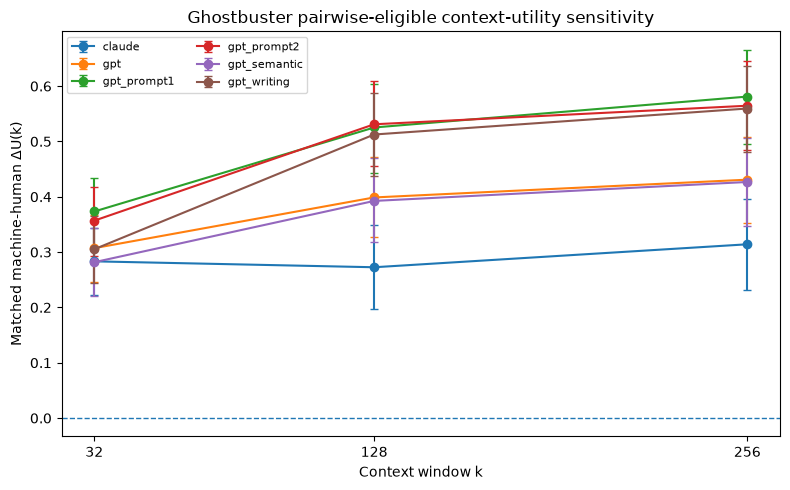

In [11]:

fig, ax = plt.subplots(figsize=(8, 5))

x = np.array([32, 128, 256])
for gen in machine_generators:
    sub = pairwise_boot[pairwise_boot["generator"] == gen].sort_values("k")
    y = sub["mean_delta"].to_numpy()
    yerr = np.vstack([
        y - sub["ci_low"].to_numpy(),
        sub["ci_high"].to_numpy() - y,
    ])
    ax.errorbar(x, y, yerr=yerr, marker="o", capsize=3, label=gen)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xticks(x)
ax.set_xlabel("Context window k")
ax.set_ylabel("Matched machine-human ΔU(k)")
ax.set_title("Ghostbuster pairwise-eligible context-utility sensitivity")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

fig_path = FIG_DIR / "ghostbuster_pairwise_eligibility_sensitivity.pdf"
fig.savefig(fig_path, bbox_inches="tight")
print(fig_path)
plt.show()



## 8. Save sensitivity tables


In [12]:

pairwise_path = OUT_DIR / "ghostbuster_pairwise_eligibility_by_generator.csv"
pooled_path = OUT_DIR / "ghostbuster_pairwise_eligibility_pooled.csv"
comparison_path = OUT_DIR / "ghostbuster_pairwise_vs_sevenway.csv"

pairwise_boot.to_csv(pairwise_path, index=False)
pooled.to_csv(pooled_path, index=False)
comparison.to_csv(comparison_path, index=False)

print(pairwise_path)
print(pooled_path)
print(comparison_path)


../results/ghostbuster_pairwise_eligibility_by_generator.csv
../results/ghostbuster_pairwise_eligibility_pooled.csv
../results/ghostbuster_pairwise_vs_sevenway.csv



## 9. Automatic interpretation


In [13]:

print("PAIRWISE-ELIGIBILITY SENSITIVITY SUMMARY")
print("----------------------------------------")

for k in [32, 128, 256]:
    row = comparison.loc[comparison["k"] == k].iloc[0]
    print(
        f"k={k:<3d}  seven-way={row['sevenway_mean']:.4f} "
        f"(n={int(row['n_sevenway'])})  "
        f"pairwise={row['pairwise_mean']:.4f} "
        f"[{row['pairwise_ci_low']:.4f}, {row['pairwise_ci_high']:.4f}] "
        f"(n={int(row['n_pairwise_sources'])})  "
        f"shift={row['difference_pairwise_minus_sevenway']:+.4f}"
    )

print("\nGenerator-specific pairwise results at k=256:")
sub = pairwise_boot[pairwise_boot["k"] == 256].sort_values("mean_delta")
for _, r in sub.iterrows():
    print(
        f"  {r['generator']:14s} "
        f"n={int(r['n_pairs']):3d} "
        f"mean={r['mean_delta']:+.4f} "
        f"CI=[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]"
    )

all_positive = (pairwise_boot["mean_delta"] > 0).all()
all_ci_positive_256 = (
    pairwise_boot.loc[pairwise_boot["k"] == 256, "ci_low"] > 0
).all()

print()
print("All generator × k point estimates positive:", all_positive)
print("All k=256 generator CIs above zero:", all_ci_positive_256)

max_abs_shift = comparison["difference_pairwise_minus_sevenway"].abs().max()

if all_positive and max_abs_shift < 0.10:
    print("\nInterpretation: the qualitative Ghostbuster result is robust to pairwise eligibility;")
    print("the strict seven-way complete-case requirement changes the sample size more than")
    print("the substantive direction of the context-utility effect.")
else:
    print("\nInterpretation: pairwise eligibility materially changes at least part of the result;")
    print("inspect generator-specific estimates before describing the seven-way finding as robust.")


PAIRWISE-ELIGIBILITY SENSITIVITY SUMMARY
----------------------------------------
k=32   seven-way=0.3162 (n=708)  pairwise=0.3186 [0.2739, 0.3620] (n=773)  shift=+0.0023
k=128  seven-way=0.4366 (n=708)  pairwise=0.4398 [0.3829, 0.4938] (n=773)  shift=+0.0032
k=256  seven-way=0.4772 (n=708)  pairwise=0.4802 [0.4232, 0.5391] (n=773)  shift=+0.0031

Generator-specific pairwise results at k=256:
  claude         n=757 mean=+0.3141 CI=[+0.2319, +0.3965]
  gpt_semantic   n=748 mean=+0.4268 CI=[+0.3472, +0.5058]
  gpt            n=747 mean=+0.4309 CI=[+0.3527, +0.5077]
  gpt_writing    n=773 mean=+0.5595 CI=[+0.4805, +0.6365]
  gpt_prompt2    n=759 mean=+0.5646 CI=[+0.4849, +0.6462]
  gpt_prompt1    n=748 mean=+0.5811 CI=[+0.4949, +0.6658]

All generator × k point estimates positive: True
All k=256 generator CIs above zero: True

Interpretation: the qualitative Ghostbuster result is robust to pairwise eligibility;
the strict seven-way complete-case requirement changes the sample size more th